In [23]:
# # Logistic Regression for Credit Card Fraud Detection

# This notebook develops a Logistic Regression model for fraud detection.

# Two approaches are evaluated to handle the class imbalance:
# 1. Class Weight
# 2. SMOTE

# Both approaches are evaluated on the same untouched test dataset.

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    ConfusionMatrixDisplay
)

In [25]:
X_train = pd.read_csv("../Data/processed/X_train.csv")
y_train = pd.read_csv("../Data/processed/y_train.csv").squeeze()

X_test = pd.read_csv("../Data/processed/X_test.csv")
y_test = pd.read_csv("../Data/processed/y_test.csv").squeeze()

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

X_train: (198608, 30)
y_train: (198608,)
X_test: (85118, 30)
y_test: (85118,)

Training Class Distribution:
Class
0    198277
1       331
Name: count, dtype: int64

Testing Class Distribution:
Class
0    84976
1      142
Name: count, dtype: int64


In [26]:
# ## Approach 1 — Logistic Regression with Class Weight

# Class Weight handles class imbalance by assigning higher importance to the minority fraud class during model training.

# The original training data is not modified.

In [27]:
model_weight = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

model_weight.fit(X_train, y_train)

print("Logistic Regression with Class Weight trained successfully.")

Logistic Regression with Class Weight trained successfully.


C:\Users\HP\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [28]:
y_pred_weight = model_weight.predict(X_test)

y_prob_weight = model_weight.predict_proba(X_test)[:, 1]

print("Predictions completed.")

Predictions completed.


In [29]:
print("Classification Report - Class Weight")

print(classification_report(y_test, y_pred_weight))

precision_weight = precision_score(y_test, y_pred_weight)
recall_weight = recall_score(y_test, y_pred_weight)
f1_weight = f1_score(y_test, y_pred_weight)

roc_auc_weight = roc_auc_score(y_test, y_prob_weight)
pr_auc_weight = average_precision_score(y_test, y_prob_weight)

print("Precision:", round(precision_weight, 4))
print("Recall:", round(recall_weight, 4))
print("F1 Score:", round(f1_weight, 4))
print("ROC AUC:", round(roc_auc_weight, 4))
print("PR AUC:", round(pr_auc_weight, 4))

Classification Report - Class Weight
              precision    recall  f1-score   support

           0       1.00      0.81      0.90     84976
           1       0.01      0.92      0.02       142

    accuracy                           0.81     85118
   macro avg       0.50      0.86      0.46     85118
weighted avg       1.00      0.81      0.90     85118

Precision: 0.0081
Recall: 0.9155
F1 Score: 0.0161
ROC AUC: 0.9524
PR AUC: 0.6587


In [30]:
cm_weight = confusion_matrix(y_test, y_pred_weight)

print("Confusion Matrix - Class Weight")

print(cm_weight)

Confusion Matrix - Class Weight
[[69074 15902]
 [   12   130]]


In [31]:
# ## Approach 2 — Logistic Regression with SMOTE

# SMOTE is applied only to the training data to create synthetic minority-class samples.

# The test data remains unchanged.

In [32]:
X_train_smote = pd.read_csv("../Data/processed/X_train_smote.csv")

y_train_smote = pd.read_csv(
    "../Data/processed/y_train_smote.csv"
).squeeze()

print("X_train_smote:", X_train_smote.shape)
print("y_train_smote:", y_train_smote.shape)

print("\nSMOTE Class Distribution:")
print(y_train_smote.value_counts())

X_train_smote: (396554, 30)
y_train_smote: (396554,)

SMOTE Class Distribution:
Class
0    198277
1    198277
Name: count, dtype: int64


In [33]:
# Logistic Regression with SMOTE

model_smote = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model_smote.fit(X_train_smote, y_train_smote)

print("SMOTE Model Trained Successfully")

SMOTE Model Trained Successfully


In [34]:
y_pred_smote = model_smote.predict(X_test)

y_prob_smote = model_smote.predict_proba(X_test)[:, 1]

print("SMOTE Predictions Completed")

SMOTE Predictions Completed


In [35]:
print("Classification Report - SMOTE")

print(classification_report(y_test, y_pred_smote))

precision_smote = precision_score(y_test, y_pred_smote)
recall_smote = recall_score(y_test, y_pred_smote)
f1_smote = f1_score(y_test, y_pred_smote)

roc_auc_smote = roc_auc_score(y_test, y_prob_smote)
pr_auc_smote = average_precision_score(y_test, y_prob_smote)

print("Precision:", round(precision_smote, 4))
print("Recall:", round(recall_smote, 4))
print("F1 Score:", round(f1_smote, 4))
print("ROC AUC:", round(roc_auc_smote, 4))
print("PR AUC:", round(pr_auc_smote, 4))

Classification Report - SMOTE
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     84976
           1       0.05      0.88      0.10       142

    accuracy                           0.97     85118
   macro avg       0.53      0.93      0.54     85118
weighted avg       1.00      0.97      0.98     85118

Precision: 0.0503
Recall: 0.8803
F1 Score: 0.0952
ROC AUC: 0.9665
PR AUC: 0.6913


In [36]:
cm_smote = confusion_matrix(y_test, y_pred_smote)

print("Confusion Matrix - SMOTE")

print(cm_smote)

Confusion Matrix - SMOTE
[[82618  2358]
 [   17   125]]


In [37]:
comparison = pd.DataFrame({
    "Metric": [
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC",
        "PR-AUC"
    ],

    "Class Weight": [
        precision_weight,
        recall_weight,
        f1_weight,
        roc_auc_weight,
        pr_auc_weight
    ],

    "SMOTE": [
        precision_smote,
        recall_smote,
        f1_smote,
        roc_auc_smote,
        pr_auc_smote
    ]
})

display(comparison.round(4))

,Metric,Class Weight,SMOTE
0,Precision,0.0081,0.0503
1,Recall,0.9155,0.8803
2,F1-score,0.0161,0.0952
3,ROC-AUC,0.9524,0.9665
4,PR-AUC,0.6587,0.6913


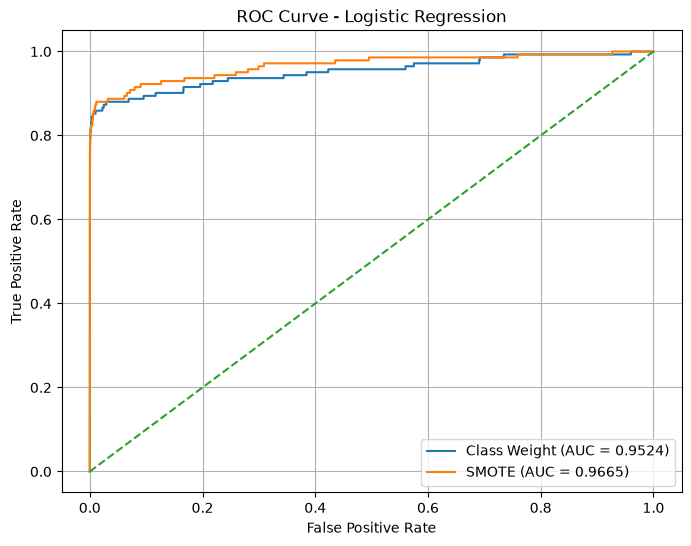

In [38]:
fpr_weight, tpr_weight, _ = roc_curve(
    y_test, y_prob_weight
)

fpr_smote, tpr_smote, _ = roc_curve(
    y_test, y_prob_smote
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_weight,
    tpr_weight,
    label=f"Class Weight (AUC = {roc_auc_weight:.4f})"
)

plt.plot(
    fpr_smote,
    tpr_smote,
    label=f"SMOTE (AUC = {roc_auc_smote:.4f})"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve - Logistic Regression")

plt.legend()
plt.grid()
plt.show()

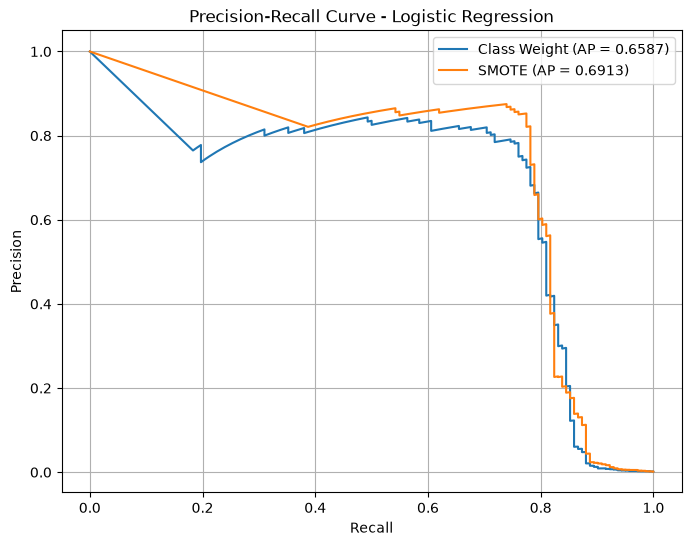

In [39]:
precision_w, recall_w, _ = precision_recall_curve(
    y_test, y_prob_weight
)

precision_s, recall_s, _ = precision_recall_curve(
    y_test, y_prob_smote
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_w,
    precision_w,
    label=f"Class Weight (AP = {pr_auc_weight:.4f})"
)

plt.plot(
    recall_s,
    precision_s,
    label=f"SMOTE (AP = {pr_auc_smote:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title("Precision-Recall Curve - Logistic Regression")

plt.legend()
plt.grid()
plt.show()

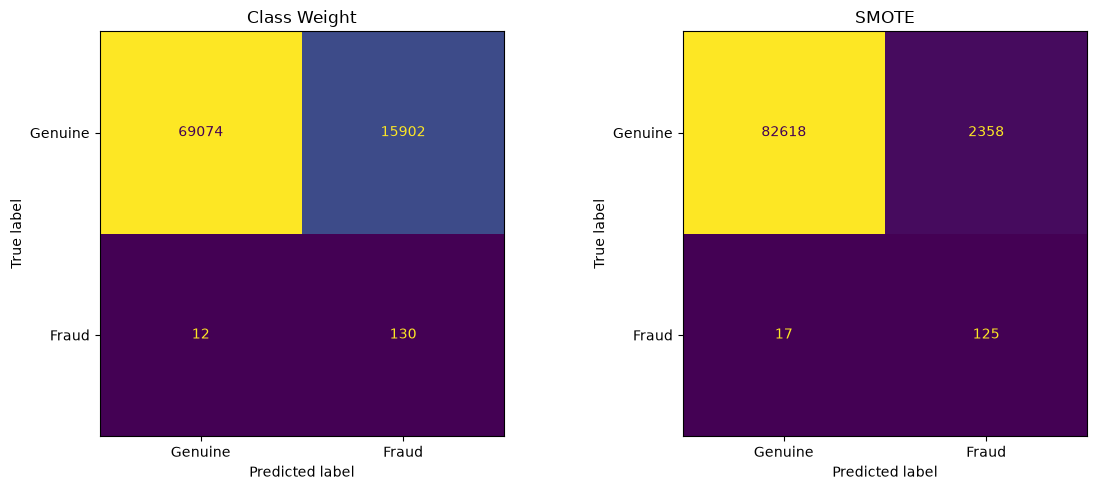

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm_weight,
    display_labels=["Genuine", "Fraud"]
).plot(ax=axes[0], colorbar=False)

axes[0].set_title("Class Weight")

ConfusionMatrixDisplay(
    confusion_matrix=cm_smote,
    display_labels=["Genuine", "Fraud"]
).plot(ax=axes[1], colorbar=False)

axes[1].set_title("SMOTE")

plt.tight_layout()
plt.show()